In [1]:
import specula
specula.init(0)

import numpy as np
import matplotlib.pyplot as plt

from astropy.io import fits
import glob
import os.path as op

2026-11-09 17:17:20,592 [INFO]: [specula]: Cupy import successfull. Installed version is: 13.3.0
2026-11-09 17:17:20,778 [INFO]: [specula]: Default device is GPU number 0


In [2]:
result_dir = '/raid1/mmenessini/results/CHAOS/'
calib_dir = '/raid1/mmenessini/calibration/CHAOS/'

In [3]:
# from specula.processing_objects.modulated_pyramid import ModulatedPyramid
# from specula.data_objects.simul_params import SimulParams

# pars = SimulParams(pixel_pupil=220,pixel_pitch=0.03)
# pyr = ModulatedPyramid(pars,wavelengthInNm=650,
#                        fov=2,pup_diam=60,pup_dist=72,
#                        output_resolution=160,
#                        pyr_tip_def_ld=0.0,
#                        pyr_edge_def_ld=0.0,
#                        pyr_tip_maya_ld=0.0,
#                        fft_res=4.0,
#                        pyr_roof_ld=1.0,
#                        mod_amp=3.0)
# s = len(pyr.pyr_tlt)
# d = 50
# plt.figure()
# plt.imshow((pyr.pyr_tlt.get()),origin='lower',vmin=125)
# plt.xlim([s//2-d,s//2+d])
# plt.ylim([s//2-d,s//2+d])
# plt.colorbar()

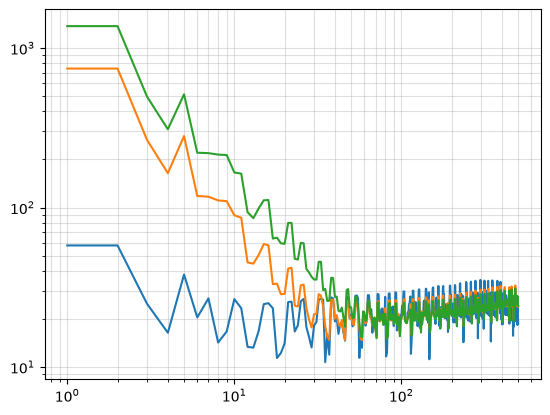

In [21]:
rec1 = fits.getdata(op.join(calib_dir,'rec','pyr1.0_dm820_rec.fits'),1)
rec3 = fits.getdata(op.join(calib_dir,'rec','pyr3.0_dm820_rec.fits'),1)
rec4 = fits.getdata(op.join(calib_dir,'rec','pyr4.0_dm820_rec.fits'),1)

plt.figure()
plt.loglog(np.arange(500)+1,np.diag(rec1 @ rec1.T))
plt.loglog(np.arange(500)+1,np.diag(rec3 @ rec3.T))
plt.loglog(np.arange(500)+1,np.diag(rec4 @ rec4.T))
plt.grid(which='both',alpha=0.4)

In [24]:
result_path = sorted(glob.glob(op.join(result_dir, '20*')))[-1]
print(result_path.split('/')[-1])

20261109_172920


Text(0.5, 1.0, 'rMod 1 frame')

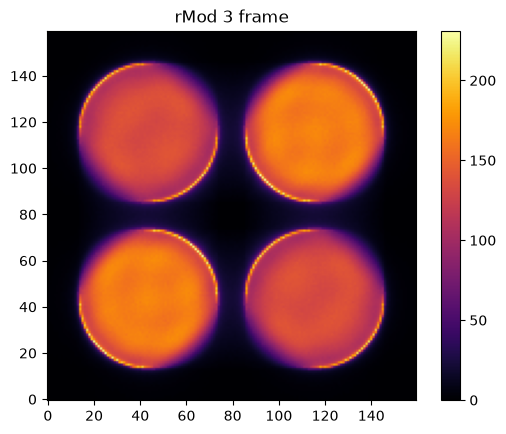

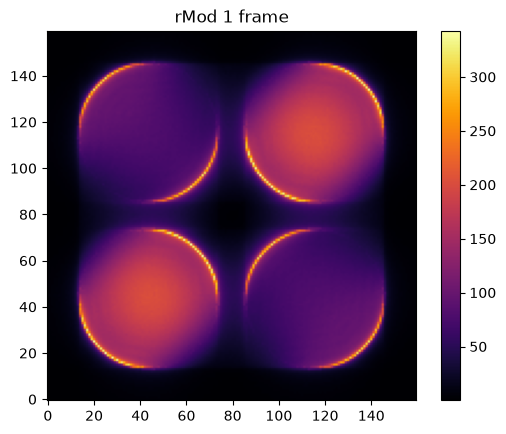

In [ ]:
tn = '20261109_172339'
result_path = op.join(result_dir,tn) #
frames = fits.getdata(op.join(result_path,'ccd.fits'))
plt.figure()
plt.imshow(np.mean(frames,axis=0),cmap='inferno',origin='lower')
plt.colorbar()
plt.title('rMod 3 frame')
tn = '20261109_172615'
result_path = op.join(result_dir,tn) #
frames = fits.getdata(op.join(result_path,'ccd.fits'))
plt.figure()
plt.imshow(np.mean(frames,axis=0),cmap='inferno',origin='lower')
plt.colorbar()
plt.title('rMod 1 frame')

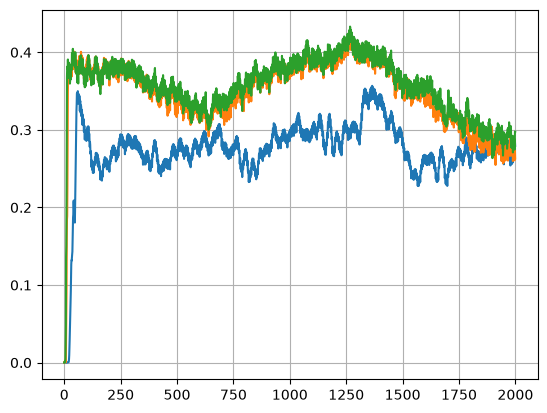

In [25]:
mod3_tn = '20261109_171645'
result_path = op.join(result_dir,mod3_tn) #sorted(glob.glob(op.join(result_dir, '20*')))[-1]
sr3 = fits.getdata(op.join(result_path,'sr.fits'))

mod4_tn = '20261109_171944'
result_path = op.join(result_dir,mod4_tn) #
sr4 = fits.getdata(op.join(result_path,'sr.fits'))

mod1_tn = '20261109_172920'
result_path = op.join(result_dir,mod1_tn) #
sr1 = fits.getdata(op.join(result_path,'sr.fits'))

plt.figure()
plt.plot(sr1)
plt.plot(sr3)
plt.plot(sr4)
plt.grid()
